In [2]:
import glob, os, json
import numpy as np
import librosa, librosa.display
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torchvision
from sklearn.metrics import balanced_accuracy_score, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")


Device: cuda NVIDIA GeForce GTX 1650


In [3]:
WAV_DIR = "DB/archive/wav"
FEATURES = "DB/emodb_logmel.npz"
SR, N_SAMPLES, WIN, HOP, N_FFT, N_MELS = 16000, 3 * 16000, 400, 160, 512, 64

EMOTIONS = {"W": "anger", "L": "boredom", "E": "disgust", "A": "fear",
            "F": "happiness", "T": "sadness", "N": "neutral"}
CLASSES = sorted(EMOTIONS.values())

def fix_length(x, n=N_SAMPLES):
    if len(x) < n:
        return np.pad(x, (0, n - len(x)))
    s = (len(x) - n) // 2
    return x[s:s + n]

def wav_to_logmel(x):
    x = x.astype(np.float32)
    x = x / (np.abs(x).max() + 1e-9)            # normaliza pelo pico (o app faz o mesmo)
    x = fix_length(x)
    S = librosa.feature.melspectrogram(y=x, sr=SR, n_fft=N_FFT, win_length=WIN,
                                       hop_length=HOP, n_mels=N_MELS)
    return librosa.power_to_db(S, ref=1.0).astype(np.float32)   # (64, 301)

if os.path.exists(FEATURES):
    d = np.load(FEATURES); X, y, spk = d["X"], d["y"], d["spk"]
else:
    X, y, spk = [], [], []
    for path in sorted(glob.glob(f"{WAV_DIR}/*.wav")):
        name = os.path.basename(path)
        x, _ = librosa.load(path, sr=SR, mono=True)
        X.append(wav_to_logmel(x)); y.append(CLASSES.index(EMOTIONS[name[5]])); spk.append(name[:2])
    X, y, spk = np.stack(X), np.array(y), np.array(spk)
    np.savez(FEATURES, X=X, y=y, spk=spk)

print(X.shape, dict(zip(CLASSES, np.bincount(y).tolist())))


(535, 64, 301) {'anger': 127, 'boredom': 81, 'disgust': 46, 'fear': 69, 'happiness': 71, 'neutral': 79, 'sadness': 62}


In [4]:
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))

class ScratchCNN(nn.Module):                     # Modelo 1: ~1,2 M parâmetros
    def __init__(self, n_classes=len(CLASSES)):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 32), conv_block(32, 64),
                                      conv_block(64, 128), conv_block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x):                        # x: (B, 1, 64, 301)
        return self.head(self.features(x))

class TransferResNet(nn.Module):                 # Modelo 2: ResNet-18 ImageNet congelada
    def __init__(self, n_classes=len(CLASSES), pretrained=True):
        super().__init__()
        weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        self.net = torchvision.models.resnet18(weights=weights)
        for p in self.net.parameters():
            p.requires_grad = False
        self.net.fc = nn.Linear(self.net.fc.in_features, n_classes)   # só essa camada treina
    def train(self, mode=True):
        super().train(mode)
        self.net.eval()                          # mantém o BatchNorm congelado
        return self
    def forward(self, x):
        return self.net(x.repeat(1, 3, 1, 1))    # 1 canal -> 3 canais (RGB)

MODELS = {"scratch": ScratchCNN, "resnet18": TransferResNet}


In [5]:
def set_seed(seed):
    np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def augment(xb, max_shift=30, max_f=8, max_t=30):
    """Deslocamento aleatório no tempo + SpecAugment (máscaras de frequência e tempo)."""
    xb = xb.clone()
    n_mels, n_frames = xb.shape[-2:]
    for i in range(len(xb)):
        xb[i] = torch.roll(xb[i], np.random.randint(-max_shift, max_shift + 1), dims=-1)
        f = np.random.randint(0, max_f + 1); f0 = np.random.randint(0, n_mels - f + 1)
        t = np.random.randint(0, max_t + 1); t0 = np.random.randint(0, n_frames - t + 1)
        xb[i, :, f0:f0 + f, :] = 0
        xb[i, :, :, t0:t0 + t] = 0
    return xb

def fit(model_name, Xtr, ytr, epochs=40, bs=32, lr=1e-3):
    Xtr, ytr = torch.tensor(Xtr).unsqueeze(1), torch.tensor(ytr)
    model = MODELS[model_name]().to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],
                           lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    counts = np.bincount(ytr.numpy(), minlength=len(CLASSES))
    w = torch.tensor(len(ytr) / (len(CLASSES) * np.maximum(counts, 1)), dtype=torch.float32)
    loss_fn = nn.CrossEntropyLoss(weight=w.to(device))   # pesos: EmoDB é desbalanceado
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(ytr)); total = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            xb, yb = augment(Xtr[idx]).to(device), ytr[idx].to(device)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        sched.step()
        if (ep + 1) % 10 == 0:
            print(f"    época {ep + 1}/{epochs}  loss {total / len(ytr):.3f}")
    return model

def predict(model, X, bs=64):
    model.eval(); preds = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = torch.tensor(X[i:i + bs]).unsqueeze(1).to(device)
            preds.append(model(xb).argmax(1).cpu())
    return torch.cat(preds).numpy()



### scratch
    época 10/40  loss 0.653
    época 20/40  loss 0.313
    época 30/40  loss 0.159
    época 40/40  loss 0.114
  fold 1 ('03', '08'): UAR 0.753
    época 10/40  loss 0.620
    época 20/40  loss 0.415
    época 30/40  loss 0.270
    época 40/40  loss 0.187
  fold 2 ('10', '09'): UAR 0.818
    época 10/40  loss 0.748
    época 20/40  loss 0.531
    época 30/40  loss 0.369
    época 40/40  loss 0.289
  fold 3 ('11', '13'): UAR 0.748
    época 10/40  loss 0.640
    época 20/40  loss 0.366
    época 30/40  loss 0.179
    época 40/40  loss 0.146
  fold 4 ('12', '14'): UAR 0.785
    época 10/40  loss 0.655
    época 20/40  loss 0.348
    época 30/40  loss 0.188
    época 40/40  loss 0.116
  fold 5 ('15', '16'): UAR 0.743
==> scratch: UAR 0.769 ± 0.029 (acaso = 0.143)


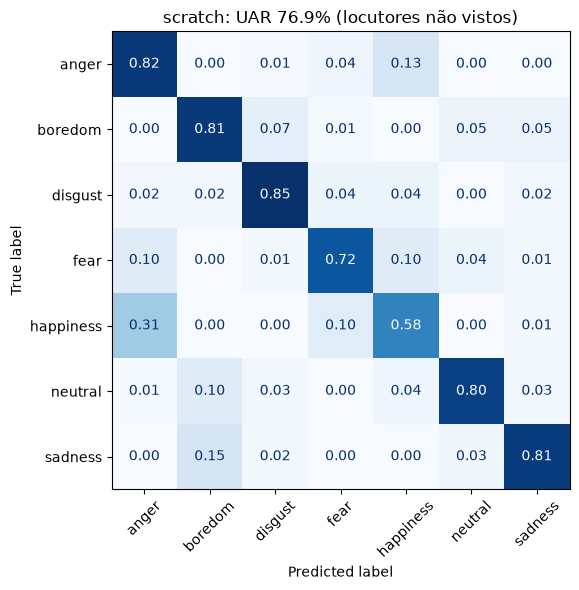


### resnet18
    época 10/40  loss 1.053
    época 20/40  loss 0.837
    época 30/40  loss 0.845
    época 40/40  loss 0.829
  fold 1 ('03', '08'): UAR 0.615
    época 10/40  loss 1.074
    época 20/40  loss 0.895
    época 30/40  loss 0.839
    época 40/40  loss 0.842
  fold 2 ('10', '09'): UAR 0.620
    época 10/40  loss 1.070
    época 20/40  loss 0.904
    época 30/40  loss 0.843
    época 40/40  loss 0.823
  fold 3 ('11', '13'): UAR 0.542
    época 10/40  loss 1.038
    época 20/40  loss 0.927
    época 30/40  loss 0.865
    época 40/40  loss 0.856
  fold 4 ('12', '14'): UAR 0.756
    época 10/40  loss 1.069
    época 20/40  loss 0.932
    época 30/40  loss 0.866
    época 40/40  loss 0.913
  fold 5 ('15', '16'): UAR 0.643
==> resnet18: UAR 0.635 ± 0.069 (acaso = 0.143)


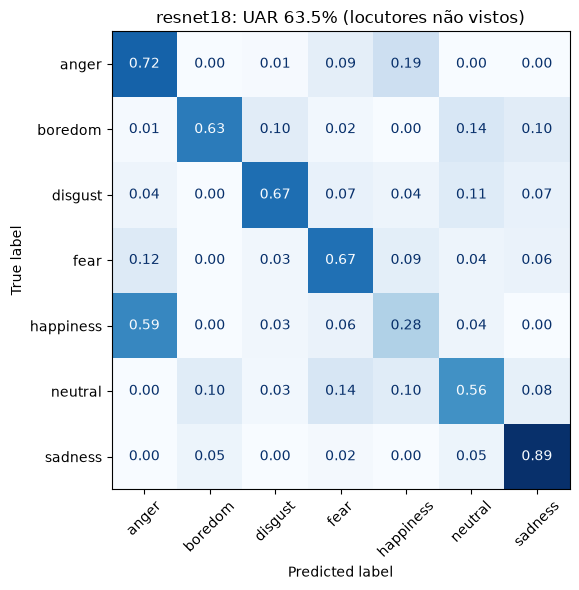

In [6]:
# cada fold separa 1 homem + 1 mulher para teste (homens: 03 10 11 12 15, mulheres: 08 09 13 14 16)
FOLDS = [("03", "08"), ("10", "09"), ("11", "13"), ("12", "14"), ("15", "16")]
EPOCHS = 40
os.makedirs("results", exist_ok=True)
metrics = {}

for name in MODELS:
    print(f"\n### {name}")
    all_pred, fold_uar = np.zeros_like(y), []
    for k, test_spk in enumerate(FOLDS):
        set_seed(k)
        te = np.isin(spk, test_spk); tr = ~te
        mu, sd = X[tr].mean(), X[tr].std()       # estatísticas só dos locutores de treino
        model = fit(name, (X[tr] - mu) / sd, y[tr], EPOCHS)
        all_pred[te] = predict(model, (X[te] - mu) / sd)
        fold_uar.append(balanced_accuracy_score(y[te], all_pred[te]))
        print(f"  fold {k + 1} {test_spk}: UAR {fold_uar[-1]:.3f}")
    metrics[name] = {"fold_uar": fold_uar, "mean_uar": float(np.mean(fold_uar)),
                     "std_uar": float(np.std(fold_uar))}
    print(f"==> {name}: UAR {np.mean(fold_uar):.3f} ± {np.std(fold_uar):.3f} (acaso = {1/len(CLASSES):.3f})")

    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(y, all_pred, display_labels=CLASSES, normalize="true",
                                            values_format=".2f", xticks_rotation=45,
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name}: UAR {np.mean(fold_uar):.1%} (locutores não vistos)")
    fig.tight_layout(); fig.savefig(f"results/confusion_{name}.png", dpi=150); plt.show()

with open("results/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)


In [7]:
os.makedirs("models", exist_ok=True)
for name in MODELS:
    set_seed(0)
    mu, sd = float(X.mean()), float(X.std())
    model = fit(name, (X - mu) / sd, y, EPOCHS)
    torch.save({"model": {k: v.cpu() for k, v in model.state_dict().items()},
                "mu": mu, "sd": sd, "classes": CLASSES}, f"models/{name}.pt")
    print("salvo", f"models/{name}.pt")


    época 10/40  loss 0.595
    época 20/40  loss 0.279
    época 30/40  loss 0.148
    época 40/40  loss 0.097
salvo models/scratch.pt
    época 10/40  loss 1.021
    época 20/40  loss 0.897
    época 30/40  loss 0.842
    época 40/40  loss 0.855
salvo models/resnet18.pt
